# Проект: FashionMNIST

Свой сквозной проект параллельно проекту автора на MNIST. После каждого видео сюда добавляется новый раздел: данные → модель → цикл обучения → scheduler → сохранение → EarlyStopping → финальный test.

| у автора | здесь |
|:---|:---|
| MNIST: цифры 0–9 | FashionMNIST: 10 видов одежды |
| 60 000 train / 10 000 test, 28×28, серые | то же самое |

Формы совпадают, поэтому видео подходит один в один. Классы другие: результат и ошибки сети будут свои.

**Правило проекта:** ячейки идут сверху вниз, каждый раздел опирается на код прошлых. Перед новым разделом перезапусти ноутбук целиком (Restart → Run All до нового раздела).

Решения — в `fashion_mnist_решения.ipynb`, только после своей попытки.

In [ ]:
import gzip
import os
import shutil
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch.utils.data import (
    Dataset,
    DataLoader,
    random_split,
    RandomSampler,
    SequentialSampler,
)

torch.manual_seed(0)


def need(cond, msg):
    assert cond, msg


def need_tensor(x, name):
    assert isinstance(x, torch.Tensor), f"{name} — пока не тензор (замени ... на код)"

---
# Видео 5. Данные → `Dataset` → `DataLoader`

У автора в этом видео: картинки по папкам-классам → свой `MnistDataset` → `random_split` → три `DataLoader`. Здесь то же самое на FashionMNIST.

## 5.0 Подготовка данных

Автор раскладывает MNIST по папкам заранее, вне видео. Ячейка ниже делает это для FashionMNIST: качает архивы (~30 МБ) и сохраняет 70 000 png в `_data/fashion/{train,test}/<класс>/`. Первый запуск — 1–3 минуты, потом ячейка видит готовые папки и ничего не делает.

Имена папок — названия одежды (`t-shirt`, `ankle-boot`, …), а не цифры: как у автора, «более общий случай».

In [ ]:
DATA = "_data"
RAW = os.path.join(DATA, "raw")
FASHION = os.path.join(DATA, "fashion")
TRAIN_DIR = os.path.join(FASHION, "train")
TEST_DIR = os.path.join(FASHION, "test")

URL = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
FILES = {
    "train": ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"),
    "test": ("t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"),
}
CLASS_NAMES = [
    "t-shirt",
    "trouser",
    "pullover",
    "dress",
    "coat",
    "sandal",
    "shirt",
    "sneaker",
    "bag",
    "ankle-boot",
]


def download(file_name):
    path = os.path.join(RAW, file_name)
    if not os.path.exists(path):
        os.makedirs(RAW, exist_ok=True)
        urllib.request.urlretrieve(URL + file_name, path)
    return path


def read_images(path):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 28, 28)


def read_labels(path):
    with gzip.open(path, "rb") as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)


def prepare_split(split):
    root = os.path.join(FASHION, split)
    if os.path.isdir(root):
        print(split, "— уже готов")
        return
    tmp = root + "_tmp"
    shutil.rmtree(tmp, ignore_errors=True)
    images_file, labels_file = FILES[split]
    images = read_images(download(images_file))
    labels = read_labels(download(labels_file))
    for name in CLASS_NAMES:
        os.makedirs(os.path.join(tmp, name))
    for k, (img, label) in enumerate(zip(images, labels)):
        Image.fromarray(img).save(
            os.path.join(tmp, CLASS_NAMES[label], f"{split}_{k:05d}.png")
        )
    os.rename(tmp, root)
    print(split, "—", len(images), "картинок")


prepare_split("train")
prepare_split("test")
print(sorted(os.listdir(TRAIN_DIR)))

train — уже готов
test — уже готов
['ankle-boot', 'bag', 'coat', 'dress', 'pullover', 'sandal', 'shirt', 'sneaker', 't-shirt', 'trouser']


## 5.1 Свой `ImageDataset`
*видео 5: 2:36–9:56*

Возьми свой `FruitsDataset` из `05` и сделай из него `ImageDataset` для этого проекта. Требования те же:

| что | требование |
|:---|:---|
| `self.classes` | отсортированные имена папок-классов |
| `self.class_to_idx` | имя → индекс |
| `self.data_list` | пары `(путь, индекс)`, только `.png` |
| `__getitem__` | `(x, label)`: `x` — `float32` `(1, 28, 28)` в `0..1`, `label` — `int` |
| `transform` | если задан — применить к `x` |

**Новое:** `self.targets` — список меток всех примеров в том же порядке, что `data_list`. Так можно считать баланс классов, не открывая 60 000 файлов (у `ImageFolder` из видео 6 такое поле тоже есть).

**Ожидаемый вывод:**

```text
['ankle-boot', 'bag', 'coat', 'dress', 'pullover', 'sandal', 'shirt', 'sneaker', 't-shirt', 'trouser']
60000 10000 torch.Size([1, 28, 28]) torch.float32 0
```

> **Важно (видео 14):** `sorted` для папок классов обязателен. Без него `class_to_idx` может плавать → после load accuracy ≈ случайная (~10% на 10 классах). В checkpoint классификации полезно сохранять и `class_to_idx` вместе с весами.

In [ ]:
class ImageDataset(Dataset):
    def __init__(self, root, transform=None):
        self.root = root
        self.transform = transform
        self.classes = sorted(
            name for name in os.listdir(root) if os.path.isdir(os.path.join(root, name))
        )
        self.class_to_idx = {name: i for i, name in enumerate(self.classes)}
        self.data_list = []
        for name in self.classes:
            folder = os.path.join(root, name)
            for file_name in sorted(os.listdir(folder)):
                if file_name.endswith(".png"):
                    self.data_list.append(
                        (os.path.join(folder, file_name), self.class_to_idx[name])
                    )
        self.targets = [label for _, label in self.data_list]

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        path, label = self.data_list[idx]
        with Image.open(path) as im:
            arr = np.array(im)  # (28, 28) uint8
        x = torch.tensor(arr, dtype=torch.float32).unsqueeze(0) / 255  # (1, 28, 28)
        if self.transform is not None:
            x = self.transform(x)
        return x, label


train_val_ds = ImageDataset(TRAIN_DIR)
test_ds = ImageDataset(TEST_DIR)
x, label = train_val_ds[0]
print(train_val_ds.classes)
print(len(train_val_ds), len(test_ds), x.shape, x.dtype, label)

['ankle-boot', 'bag', 'coat', 'dress', 'pullover', 'sandal', 'shirt', 'sneaker', 't-shirt', 'trouser']
60000 10000 torch.Size([1, 28, 28]) torch.float32 0


In [ ]:
need(train_val_ds.classes == sorted(CLASS_NAMES), f"classes={train_val_ds.classes}")
need(
    train_val_ds.class_to_idx == {n: i for i, n in enumerate(sorted(CLASS_NAMES))},
    "class_to_idx не по порядку classes",
)
need(
    test_ds.class_to_idx == train_val_ds.class_to_idx,
    "у train и test должно быть одно соответствие класс → индекс",
)
need(
    len(train_val_ds) == 60000 and len(test_ds) == 10000,
    f"длины {len(train_val_ds)}, {len(test_ds)}; ждали 60000 и 10000",
)
need(isinstance(train_val_ds.data_list[0][0], str), "в data_list — пути, а не картинки")
need(
    len(train_val_ds.targets) == len(train_val_ds), "targets — по одной метке на пример"
)
need(
    train_val_ds.targets[:5] == [lbl for _, lbl in train_val_ds.data_list[:5]],
    "targets в том же порядке, что data_list",
)

need_tensor(x, "x")
need(
    x.shape == (1, 28, 28) and x.dtype == torch.float32,
    f"x: {tuple(x.shape)}, {x.dtype}; ждали (1, 28, 28), float32",
)
need(0.0 <= x.min().item() and x.max().item() <= 1.0, "значения в 0..1")
need(isinstance(label, int), f"label — int, а не {type(label).__name__}")

_names = train_val_ds.classes
for _i in torch.randint(0, len(train_val_ds), (200,)).tolist():
    _path = train_val_ds.data_list[_i][0]
    _folder = os.path.basename(os.path.dirname(_path))
    need(
        _names[train_val_ds[_i][1]] == _folder,
        f"пример {_i}: метка не совпала с папкой {_folder}",
    )
print("5.1 — верно")

5.1 — верно


## 5.2 Баланс классов
*видео 5: 4:44–5:45*

Автор смотрит на число картинок в каждом классе MNIST и видит лёгкий перекос. Посчитай то же для FashionMNIST через `train_val_ds.targets` (`torch.bincount`), без чтения файлов.

`counts` — словарь имя класса → число картинок; `is_balanced` — `True` / `False`.

**Ожидаемый вывод:**

```text
{'ankle-boot': 6000, 'bag': 6000, 'coat': 6000, ..., 'trouser': 6000} True
```

In [ ]:
_n = torch.bincount(
    torch.tensor(train_val_ds.targets), minlength=len(train_val_ds.classes)
)
counts = {name: _n[i].item() for i, name in enumerate(train_val_ds.classes)}
is_balanced = True  # ровно по 6000 в каждом
print(counts, is_balanced)

{'ankle-boot': 6000, 'bag': 6000, 'coat': 6000, 'dress': 6000, 'pullover': 6000, 'sandal': 6000, 'shirt': 6000, 'sneaker': 6000, 't-shirt': 6000, 'trouser': 6000} True


In [ ]:
need(
    isinstance(counts, dict) and set(counts) == set(CLASS_NAMES),
    "ключи counts — имена классов",
)
need(all(v == 6000 for v in counts.values()), f"counts={counts}")
need(
    is_balanced is True,
    "по 6000 в каждом классе — идеальный баланс (в отличие от MNIST у автора)",
)
print("5.2 — верно")

5.2 — верно


## 5.3 train / val и три `DataLoader`
*видео 5: 14:07–15:41*

Как у автора: от 60 000 train отрезаем val — 48 000 / 12 000, seed 42. Размер батча — 64 (у автора 16; посмотри, как это изменит число батчей).

Сначала **посчитай в уме** `pred`: пары `(число_батчей, размер_последнего)` для train, val, test. Проверка сравнит с `len(loader)` — без прохода по 70 000 файлам.

**Ожидаемый вывод:**

```text
48000 12000 torch.Size([64, 1, 28, 28]) torch.Size([64])
```

In [ ]:
train_ds, val_ds = random_split(
    train_val_ds, [48000, 12000], generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

pred = {
    "train": (750, 64),  # 48000 / 64 = 750 ровно
    "val": (188, 32),  # 187 полных + 12000 - 187 * 64 = 32
    "test": (157, 16),  # 156 полных + 10000 - 156 * 64 = 16
}

xb, yb = next(iter(train_loader))
print(len(train_ds), len(val_ds), xb.shape, yb.shape)

48000 12000 torch.Size([64, 1, 28, 28]) torch.Size([64])


In [ ]:
need(
    len(train_ds) == 48000 and len(val_ds) == 12000,
    f"длины {len(train_ds)}, {len(val_ds)}",
)
need(not (set(train_ds.indices) & set(val_ds.indices)), "train и val пересекаются")
_again, _ = random_split(
    train_val_ds, [48000, 12000], generator=torch.Generator().manual_seed(42)
)
need(
    list(_again.indices[:10]) == list(train_ds.indices[:10]),
    "нужен generator с seed 42",
)

need(isinstance(train_loader.sampler, RandomSampler), "train — shuffle=True")
need(
    isinstance(val_loader.sampler, SequentialSampler)
    and isinstance(test_loader.sampler, SequentialSampler),
    "val и test — без перемешивания",
)
for _name, _loader in {
    "train": train_loader,
    "val": val_loader,
    "test": test_loader,
}.items():
    need(_loader.batch_size == BATCH_SIZE, f"{_name}: batch_size={_loader.batch_size}")
    _n = len(_loader.dataset)
    _real = (len(_loader), _n - (len(_loader) - 1) * BATCH_SIZE)
    need(pred[_name] == _real, f"{_name}: ты предсказал {pred[_name]}, на деле {_real}")
need(xb.shape == (64, 1, 28, 28), f"xb.shape={tuple(xb.shape)}, ждали (64, 1, 28, 28)")
need(
    yb.shape == (64,) and yb.dtype == torch.int64, f"yb: {tuple(yb.shape)}, {yb.dtype}"
)
print("5.3 — верно")

5.3 — верно


## 5.4 Посмотреть глазами
*видео 5: 13:03–14:07*

Автор проверяет датасет картинкой: совпадает ли подпись с изображением. Сделай `idx_to_class` (индекс → имя), ячейка ниже нарисует 16 картинок из батча `xb` с подписями. Проверь глазами, что подписи правильные: так ловятся ошибки, которые `assert` не видит.

**Ожидаемый вывод:**

```text
(картинка: 2 ряда по 8 вещей, над каждой — название класса)
5.4 — верно
```

In [9]:
idx_to_class = {i: name for name, i in train_val_ds.class_to_idx.items()}

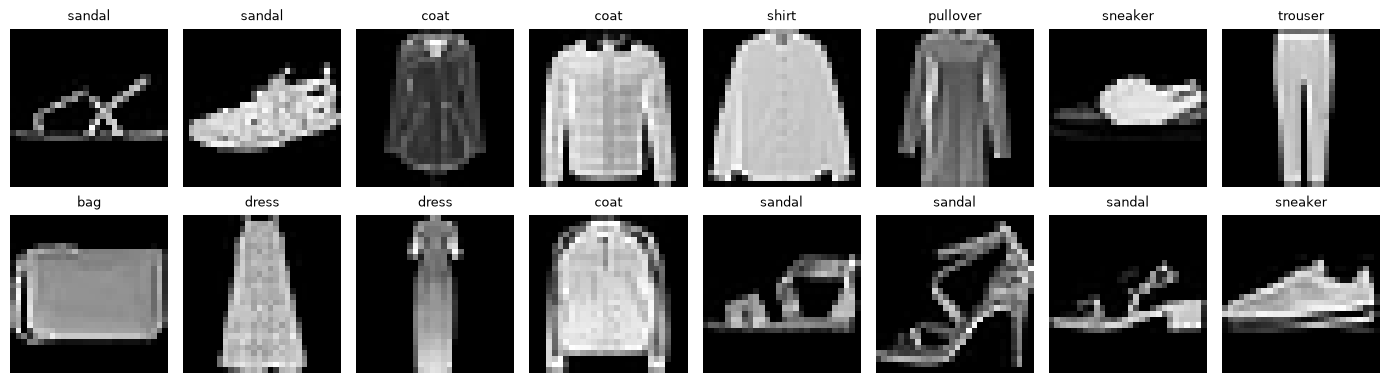

5.4 — верно


In [ ]:
need(
    idx_to_class == dict(enumerate(train_val_ds.classes)),
    f"idx_to_class={idx_to_class}",
)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lbl in zip(axes.flat, xb[:16], yb[:16]):
    ax.imshow(img[0], cmap="gray")  # img: (1, 28, 28) → img[0]: (28, 28)
    ax.set_title(idx_to_class[lbl.item()], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("5.4 — верно")

**Итог раздела «Видео 5»:** есть `train_loader`, `val_loader`, `test_loader`, батч `(64, 1, 28, 28)` + метки `(64,)`.

Дальше — раздел **Видео 6** ниже (`ImageFolder` + квадраты).


---
# Видео 6. `ImageFolder` + регрессия (квадраты)

Сначала мини-практика в `06/06_dataset_dataloader_3.ipynb`, потом этот раздел.

| у автора | здесь |
|:---|:---|
| `ImageFolder` на MNIST | `ImageFolder` на Fashion (те же папки, что для `ImageDataset`) |
| квадрат → центр `(2,)` | то же: квадрат 15×15 → `(cx, cy)` формы `(2,)` |

Нужен `torchvision` (уже для `06`). Импорты ниже дополняют ячейку в начале ноутбука.


In [ ]:
import json

from PIL import ImageDraw
from torchvision.datasets import ImageFolder
from torchvision.transforms import Compose, Grayscale, ToTensor

GRAY_TENSOR = Compose([Grayscale(num_output_channels=1), ToTensor()])

## 6.1 Fashion через `ImageFolder`

Те же `TRAIN_DIR` / `TEST_DIR`. Сравни с своим `ImageDataset`: длины и `class_to_idx` должны совпасть; батч — `(64, 1, 28, 28)`.

**Подсказка:** `ImageFolder(..., transform=GRAY_TENSOR)`. Без `Grayscale` будет 3 канала.


In [ ]:
# 6.1
train_if = ImageFolder(TRAIN_DIR, transform=GRAY_TENSOR)
test_if = ImageFolder(TEST_DIR, transform=GRAY_TENSOR)

gen6 = torch.Generator().manual_seed(0)
train_if_part, val_if_part = random_split(train_if, [50000, 10000], generator=gen6)

train_if_loader = DataLoader(train_if_part, batch_size=64, shuffle=True)
val_if_loader = DataLoader(val_if_part, batch_size=64, shuffle=False)
test_if_loader = DataLoader(test_if, batch_size=64, shuffle=False)

xb6, yb6 = next(iter(train_if_loader))
print(train_if.classes[:3], "...", len(train_if.classes))
print(len(train_if), len(test_if), xb6.shape, yb6.shape)

['ankle-boot', 'bag', 'coat'] ... 10
60000 10000 torch.Size([64, 1, 28, 28]) torch.Size([64])


In [ ]:
need(
    train_if.classes == train_val_ds.classes, f"classes ImageFolder={train_if.classes}"
)
need(
    dict(train_if.class_to_idx) == train_val_ds.class_to_idx,
    "class_to_idx должен совпасть с ImageDataset",
)
need(
    len(train_if) == 60000 and len(test_if) == 10000,
    f"длины {len(train_if)}, {len(test_if)}",
)
need(tuple(xb6.shape) == (64, 1, 28, 28), f"xb6.shape={tuple(xb6.shape)}")
need(tuple(yb6.shape) == (64,), f"yb6.shape={tuple(yb6.shape)}")
print("6.1 — верно")

6.1 — верно


## 6.2 Данные для регрессии (квадраты)

Ячейка создаёт `_data/squares/`: 2000 картинок 64×64 со светлым квадратом 15×15 и `labels.json` с `[cx, cy]`. У автора 100 000 — нам для пайплайна хватит меньше (модель подключим позже).


In [ ]:
SQUARES_DIR = os.path.join(DATA, "squares")
SQUARES_LABELS = os.path.join(SQUARES_DIR, "labels.json")


def _draw_square(cx, cy, side=15, size=64):
    img = Image.new("L", (size, size), color=30)
    draw = ImageDraw.Draw(img)
    half = side // 2
    draw.rectangle(
        [cx - half, cy - half, cx - half + side - 1, cy - half + side - 1], fill=220
    )
    return img


def prepare_squares(n=2000, size=64, side=15, seed=0):
    if os.path.isfile(SQUARES_LABELS):
        print("squares — уже готовы")
        return
    os.makedirs(SQUARES_DIR, exist_ok=True)
    rng = np.random.default_rng(seed)
    half = side // 2
    labels = {}
    for i in range(n):
        name = f"img_{i:04d}.png"
        cx = int(rng.integers(half, size - half))
        cy = int(rng.integers(half, size - half))
        _draw_square(cx, cy, side=side, size=size).save(os.path.join(SQUARES_DIR, name))
        labels[name] = [float(cx), float(cy)]
    with open(SQUARES_LABELS, "w", encoding="utf-8") as f:
        json.dump(labels, f)
    print("squares —", n, "картинок")


prepare_squares()
print("labels:", SQUARES_LABELS)

squares — 2000 картинок
labels: _data\squares\labels.json


## 6.3 `SquaresDataset`

Как в `06`, но уже в проекте. Ответ `(2,)`: `cx, cy`. Потом три `DataLoader` (1400 / 300 / 300 при batch 64).


In [ ]:
# 6.3
class SquaresDataset(Dataset):
    def __init__(self, root):
        self.root = root
        self.names = sorted(n for n in os.listdir(root) if n.endswith(".png"))
        with open(os.path.join(root, "labels.json"), encoding="utf-8") as f:
            self.labels = json.load(f)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]
        arr = (
            np.array(Image.open(os.path.join(self.root, name)), dtype=np.float32)
            / 255.0
        )
        x = torch.from_numpy(arr).unsqueeze(0)
        y = torch.tensor(self.labels[name], dtype=torch.float32)
        return x, y


squares_ds = SquaresDataset(SQUARES_DIR)
sx0, sy0 = squares_ds[0]
print(len(squares_ds), sx0.shape, sy0.shape, sy0.tolist())

gen_s = torch.Generator().manual_seed(0)
sq_train, sq_val, sq_test = random_split(squares_ds, [1400, 300, 300], generator=gen_s)

sq_train_loader = DataLoader(sq_train, batch_size=64, shuffle=True)
sq_val_loader = DataLoader(sq_val, batch_size=64, shuffle=False)
sq_test_loader = DataLoader(sq_test, batch_size=64, shuffle=False)

sxb, syb = next(iter(sq_train_loader))
print(sxb.shape, syb.shape)

2000 torch.Size([1, 64, 64]) torch.Size([2]) [49.0, 38.0]
torch.Size([64, 1, 64, 64]) torch.Size([64, 2])


In [ ]:
need(len(squares_ds) == 2000, f"len={len(squares_ds)}")
need_tensor(sx0, "sx0")
need_tensor(sy0, "sy0")
need(tuple(sx0.shape) == (1, 64, 64), f"sx0.shape={tuple(sx0.shape)}")
need(tuple(sy0.shape) == (2,), f"sy0.shape={tuple(sy0.shape)}")
need(
    (len(sq_train), len(sq_val), len(sq_test)) == (1400, 300, 300), "split 1400/300/300"
)
need(tuple(sxb.shape) == (64, 1, 64, 64), f"sxb.shape={tuple(sxb.shape)}")
need(tuple(syb.shape) == (64, 2), f"syb.shape={tuple(syb.shape)}")
print("6.3 — верно")

6.3 — верно


**Итог раздела «Видео 6»:** Fashion через `ImageFolder`; регрессия на квадратах `(B, 1, 64, 64)` → `(B, 2)`.

Дальше — раздел **Видео 7** ниже (transforms v2).


---
# Видео 7. Transforms (v2) на Fashion и квадратах

Сначала практика `07/07_transforms_v2.ipynb`. Здесь — те же идеи в проекте.

| train | val / test |
|:---|:---|
| аугментация + тензор + Normalize | только тензор + Normalize (без случайных flip) |

Для серого Fashion: `Grayscale(1)` → `ToImage` → (опционально flip) → `ToDtype(float32, scale=True)` → `Normalize((0.5,), (0.5,))`.


In [ ]:
from torchvision.transforms import v2

## 7.1 Цепочки transform для Fashion

Собери `train_tf` (с `RandomHorizontalFlip(p=0.5)`) и `eval_tf` (без flip).


In [ ]:
# 7.1
train_tf = v2.Compose(
    [
        v2.Grayscale(num_output_channels=1),
        v2.ToImage(),
        v2.RandomHorizontalFlip(p=0.5),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=(0.5,), std=(0.5,)),
    ]
)
eval_tf = v2.Compose(
    [
        v2.Grayscale(num_output_channels=1),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=(0.5,), std=(0.5,)),
    ]
)

train_if7_full = ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = ImageFolder(TRAIN_DIR, transform=eval_tf)
test_if7 = ImageFolder(TEST_DIR, transform=eval_tf)

gen7 = torch.Generator().manual_seed(0)
train7, _ = random_split(train_if7_full, [50000, 10000], generator=gen7)
_, val7 = random_split(
    full_eval, [50000, 10000], generator=torch.Generator().manual_seed(0)
)

train7_loader = DataLoader(train7, batch_size=64, shuffle=True)
val7_loader = DataLoader(val7, batch_size=64, shuffle=False)
test7_loader = DataLoader(test_if7, batch_size=64, shuffle=False)

xb7, yb7 = next(iter(train7_loader))
print(xb7.shape, yb7.shape, float(xb7.min()), float(xb7.max()))

torch.Size([64, 1, 28, 28]) torch.Size([64]) -1.0 1.0


In [ ]:
need(tuple(xb7.shape) == (64, 1, 28, 28), f"xb7={tuple(xb7.shape)}")
need(tuple(yb7.shape) == (64,), f"yb7={tuple(yb7.shape)}")
need(float(xb7.min()) < 0.0, "после Normalize(0.5) min обычно < 0")
print("7.1 — верно")

7.1 — верно


## 7.2 Квадраты с transform

Пересоздай `SquaresDataset`: картинка как PIL + `transform`, координаты `float32` `(2,)`.
Flip здесь не добавляем — иначе надо зеркалить `cx`.


In [ ]:
# 7.2
sq_tf = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=(0.5,), std=(0.5,)),
    ]
)


class SquaresDataset(Dataset):
    def __init__(self, root, transform=None):
        self.root = root
        self.transform = transform
        self.names = sorted(n for n in os.listdir(root) if n.endswith(".png"))
        with open(os.path.join(root, "labels.json"), encoding="utf-8") as f:
            self.labels = json.load(f)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]
        img = Image.open(os.path.join(self.root, name))
        if self.transform is not None:
            img = self.transform(img)
        coords = torch.tensor(self.labels[name], dtype=torch.float32)
        return img, coords


squares_ds7 = SquaresDataset(SQUARES_DIR, transform=sq_tf)
s0, c0 = squares_ds7[0]
print(s0.shape, c0.shape, c0.tolist())

torch.Size([1, 64, 64]) torch.Size([2]) [49.0, 38.0]


In [ ]:
need_tensor(s0, "s0")
need_tensor(c0, "c0")
need(tuple(s0.shape) == (1, 64, 64), f"s0={tuple(s0.shape)}")
need(tuple(c0.shape) == (2,), f"c0={tuple(c0.shape)}")
print("7.2 — верно")

7.2 — верно


**Итог «Видео 7»:** данные проекта проходят через v2-цепочки; train может отличаться аугментациями от val/test.

Видео 8 в проект отдельным блоком не переносили (см. заметку ниже). Дальше — **Видео 9** (класс модели).


## Видео 8 в проекте — пока без отдельного раздела

В тренажёре `08/` loss / метрики / Adam уже разобраны. **Отдельно в проект не переносили:** здесь ещё нет стабильного класса модели и цикла по эпохам — один «ручной» шаг Adam на Fashion дублировал бы 08 и плохо стыковался с пайплайном.

**Дальше по делу:**
- **видео 9–10** — класс `nn.Module` под Fashion и квадраты (раздел ниже / следующий);
- **видео 11** — цикл train/val: вот тогда CE/MSE, метрика и Adam встанут на место в проекте;
- scheduler / save / early stop — видео 12–14.


# Видео 9. Класс модели для проекта

После тренажёра `09/` перенеси идею: Fashion и квадраты — **свой** `nn.Module`.

> **Конспект:** [`d.4.1`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.1 Полносвязные нейронные сети.md) §5–7. Тренажёр: `../09/09_классы_нейросетей.ipynb`.

| задача | картинка на входе | после сплющивания | выход |
|:---|:---|:---|:---|
| Fashion | `(B, 1, 28, 28)` | `(B, 784)` | 10 логитов |
| квадраты | `(B, 1, 64, 64)` | `(B, 4096)` | 2 числа (cx, cy) |

### `nn.Flatten` — чего не было в тренажёре 09

В `09/` на вход `Linear` сразу шёл вектор `(B, 784)`.  
В проекте DataLoader отдаёт **картинку** `(B, C, H, W)`. Полносвязный слой хочет **последнюю ось = число признаков**, поэтому в начале `forward` (или в `Sequential`) ставят:

```python
self.flatten = nn.Flatten()   # по умолчанию сплющивает все оси, кроме батча
# (B, 1, 28, 28) → (B, 784)
# (B, 1, 64, 64) → (B, 4096)
```

То же руками: `x = x.reshape(x.shape[0], -1)`. В модели удобнее модуль `Flatten`.


In [ ]:
import torch.nn as nn

# 9.1 Два класса-модели


class FashionMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layer_1 = nn.Linear(28 * 28, hidden)
        self.act = nn.ReLU()
        self.layer_2 = nn.Linear(hidden, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.layer_1(x)
        x = self.act(x)
        x = self.layer_2(x)
        return x


class SquaresMLP(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.flatten = nn.Flatten()
        self.layer_1 = nn.Linear(64 * 64, hidden)
        self.act = nn.ReLU()
        self.layer_2 = nn.Linear(hidden, 2)

    def forward(self, x):
        x = self.flatten(x)
        x = self.layer_1(x)
        x = self.act(x)
        x = self.layer_2(x)
        return x


torch.manual_seed(0)
fashion_mlp = FashionMLP()
squares_mlp = SquaresMLP()
yf = fashion_mlp(torch.randn(8, 1, 28, 28))
ys = squares_mlp(torch.randn(8, 1, 64, 64))
print("Fashion:", tuple(yf.shape), "| squares:", tuple(ys.shape))

In [ ]:
need(
    isinstance(fashion_mlp, nn.Module) and isinstance(squares_mlp, nn.Module),
    "нужны nn.Module",
)
need(tuple(yf.shape) == (8, 10), f"Fashion out {tuple(yf.shape)}")
need(tuple(ys.shape) == (8, 2), f"squares out {tuple(ys.shape)}")
print("9.1 — верно")

**Итог «Видео 9»:** модели проекта — классы с `forward`. Дальше — методы + loss/Adam (**Видео 10** ниже); цикл — видео 11.

## Видео 10 — методы модели + loss / Adam

Сначала тренажёр [`../10/10_создание_нейросетей.ipynb`](../10/10_создание_нейросетей.ipynb).

Модели `FashionMLP` / `SquaresMLP` уже есть (видео 9). Здесь — то, что автор делает в конце видео 10:

1. `state_dict` / число параметров — проверить, что веса на месте;
2. `train()` / `eval()` — привычка до цикла;
3. `CrossEntropyLoss` + `Adam` для Fashion, `MSELoss` + `Adam` для квадратов.

Цикл обучения (батчи, эпохи, backward) — **видео 11**.

In [ ]:
# 10.1 Loss + Adam для обеих моделей проекта
criterion_f = nn.CrossEntropyLoss()
opt_f = torch.optim.Adam(fashion_mlp.parameters(), lr=1e-3)
criterion_s = nn.MSELoss()
opt_s = torch.optim.Adam(squares_mlp.parameters(), lr=1e-3)

keys_f = list(fashion_mlp.state_dict().keys())
n_f = sum(p.numel() for p in fashion_mlp.parameters())
n_s = sum(p.numel() for p in squares_mlp.parameters())

fashion_mlp.train()
flag_train = fashion_mlp.training
fashion_mlp.eval()
flag_eval = fashion_mlp.training

print("keys_f:", keys_f)
print("n_f:", n_f, "| n_s:", n_s)
print("train→", flag_train, "| eval→", flag_eval)
print("opt:", type(opt_f).__name__, type(opt_s).__name__)

In [ ]:
need(
    isinstance(criterion_f, nn.CrossEntropyLoss), "criterion_f = nn.CrossEntropyLoss()"
)
need(isinstance(criterion_s, nn.MSELoss), "criterion_s = nn.MSELoss()")
need(
    isinstance(opt_f, torch.optim.Adam) and isinstance(opt_s, torch.optim.Adam),
    "Adam(model.parameters(), lr=1e-3)",
)
need(
    set(keys_f) == {"layer_1.weight", "layer_1.bias", "layer_2.weight", "layer_2.bias"},
    f"keys_f={keys_f} — Flatten без весов, ждали только layer_1/layer_2",
)
need(n_f == 784 * 128 + 128 + 128 * 10 + 10, f"n_f={n_f}")
need(n_s == 64 * 64 * 128 + 128 + 128 * 2 + 2, f"n_s={n_s}")
need(flag_train is True and flag_eval is False, "train() → True, eval() → False")
print("10.1 — верно")

**Итог «Видео 10»:** loss и Adam на месте. Дальше — **Видео 11** (цикл train→val).

## Видео 11 — цикл обучения train → val

Сначала тренажёр [`../11/11_цикл_обучения.ipynb`](../11/11_цикл_обучения.ipynb).

Нужны переменные из прошлых разделов: `train_loader` / `val_loader`, `sq_train_loader` / `sq_val_loader` (или как у тебя названы), `fashion_mlp` / `squares_mlp`, `criterion_f` / `opt_f`, `criterion_s` / `opt_s`. Если ядро чистое — прогони ячейки сверху до Видео 10.

**Важно:**
- метки Fashion — **индексы** `(B,)`, не one-hot (`CrossEntropyLoss` как в 08);
- `Flatten` уже в модели → батч `(B,1,28,28)` подаём как есть;
- для старта хватит **3 эпох** (у автора 50 — долго на CPU и для первого раза избыточно).

> **Конспект:** [`d.4.1`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.1 Полносвязные нейронные сети.md) §11.

In [ ]:
# 11.1 Fashion: 3 эпохи train → val
EPOCHS_F = 3
hist_f = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(EPOCHS_F):
    fashion_mlp.train()
    tr_losses, tr_correct, tr_n = [], 0, 0
    for xb, yb in train_loader:
        logits = fashion_mlp(xb)
        loss = criterion_f(logits, yb)
        opt_f.zero_grad()
        loss.backward()
        opt_f.step()
        tr_losses.append(loss.item())
        pred = logits.argmax(dim=1)
        tr_correct += (pred == yb).sum().item()
        tr_n += yb.size(0)
    hist_f["train_loss"].append(sum(tr_losses) / len(tr_losses))
    hist_f["train_acc"].append(tr_correct / tr_n)

    fashion_mlp.eval()
    va_losses, va_correct, va_n = [], 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            logits = fashion_mlp(xb)
            loss = criterion_f(logits, yb)
            va_losses.append(loss.item())
            pred = logits.argmax(dim=1)
            va_correct += (pred == yb).sum().item()
            va_n += yb.size(0)
    hist_f["val_loss"].append(sum(va_losses) / len(va_losses))
    hist_f["val_acc"].append(va_correct / va_n)

    print(
        f"epoch {epoch+1}/{EPOCHS_F}  "
        f"train_loss={hist_f['train_loss'][-1]:.4f} acc={hist_f['train_acc'][-1]:.3f}  "
        f"val_loss={hist_f['val_loss'][-1]:.4f} acc={hist_f['val_acc'][-1]:.3f}"
    )

In [ ]:
need(len(hist_f["train_loss"]) == EPOCHS_F, "заполни hist_f по эпохам")
need(
    hist_f["train_loss"][-1] < hist_f["train_loss"][0],
    "train_loss должен упасть за 3 эпохи",
)
need(
    hist_f["val_acc"][-1] > 0.5,
    f"val_acc={hist_f['val_acc'][-1]:.3f} — слишком низко, проверь цикл",
)
print("11.1 — верно")

In [ ]:
# 11.2 Квадраты: 5 эпох, MSE + «точность» через округление
EPOCHS_S = 5
hist_s = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS_S):
    squares_mlp.train()
    tr_losses = []
    for xb, yb in sq_train_loader:
        pred = squares_mlp(xb)
        loss = criterion_s(pred, yb)
        opt_s.zero_grad()
        loss.backward()
        opt_s.step()
        tr_losses.append(loss.item())
    hist_s["train_loss"].append(sum(tr_losses) / len(tr_losses))

    squares_mlp.eval()
    va_losses, va_correct, va_n = [], 0, 0
    with torch.no_grad():
        for xb, yb in sq_val_loader:
            pred = squares_mlp(xb)
            loss = criterion_s(pred, yb)
            va_losses.append(loss.item())
            ok = (pred.round() == yb).all(dim=1)
            va_correct += ok.sum().item()
            va_n += yb.size(0)
    hist_s["val_loss"].append(sum(va_losses) / len(va_losses))
    hist_s["val_acc"].append(va_correct / va_n)

    print(
        f"epoch {epoch+1}/{EPOCHS_S}  "
        f"train_loss={hist_s['train_loss'][-1]:.4f}  "
        f"val_loss={hist_s['val_loss'][-1]:.4f} acc≈{hist_s['val_acc'][-1]:.3f}"
    )

In [ ]:
need(len(hist_s["train_loss"]) == EPOCHS_S, "заполни hist_s")
need(hist_s["train_loss"][-1] < hist_s["train_loss"][0], "train MSE должен упасть")
print("11.2 — верно")

**Итог «Видео 11»:** цикл train→val есть. Дальше — **Видео 12** (scheduler).

## Видео 12 — LR Scheduler

Сначала тренажёр [`../12/12_lr_scheduler.ipynb`](../12/12_lr_scheduler.ipynb)  
(`StepLR`, `MultiStepLR`, `ExponentialLR`, главное — `ReduceLROnPlateau`).

В проекте на быстрых **квадратах** вставим `StepLR`: lr падает по расписанию (как ручное уменьшение в видео 11, только автоматом).  
`ReduceLROnPlateau` на 3–8 эпохах Fashion/квадратов часто **не успевает** сработать, если val ещё улучшается — его отрабатываешь в тренажёре 12/.

> **Конспект:** [`d.4.2`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.2 Градиентная оптимизация.md) §2.6.

In [ ]:
# 12.1 StepLR на квадратах
from torch.optim.lr_scheduler import StepLR

torch.manual_seed(0)
squares_mlp = SquaresMLP()
opt_s12 = torch.optim.Adam(squares_mlp.parameters(), lr=1e-2)
sched_s = StepLR(opt_s12, step_size=2, gamma=0.5)

EPOCHS_S12 = 6
hist_lr = []
hist_val = []

for epoch in range(EPOCHS_S12):
    squares_mlp.train()
    for xb, yb in sq_train_loader:
        pred = squares_mlp(xb)
        loss = criterion_s(pred, yb)
        opt_s12.zero_grad()
        loss.backward()
        opt_s12.step()

    squares_mlp.eval()
    va_losses = []
    with torch.no_grad():
        for xb, yb in sq_val_loader:
            va_losses.append(criterion_s(squares_mlp(xb), yb).item())
    val_loss = sum(va_losses) / len(va_losses)

    hist_lr.append(opt_s12.param_groups[0]["lr"])
    sched_s.step()
    hist_val.append(val_loss)
    print(
        f"epoch {epoch+1}/{EPOCHS_S12}  val_loss={val_loss:.4f}  lr={hist_lr[-1]:.6f}"
    )

print("lrs:", hist_lr)

In [ ]:
from torch.optim.lr_scheduler import StepLR as _StepLR

need(isinstance(sched_s, _StepLR), "sched_s = StepLR(opt_s12, step_size=2, gamma=0.5)")
need(len(hist_lr) == EPOCHS_S12, "заполни hist_lr по эпохам")
need(abs(hist_lr[0] - 1e-2) < 1e-12, f"стартовый lr={hist_lr[0]}")
need(abs(hist_lr[2] - 5e-3) < 1e-9, f"после 2 step lr≈0.005, а {hist_lr[2]}")
need(hist_lr[-1] < hist_lr[0], f"lr должен упасть: {hist_lr}")
print("12.1 — верно")

**Итог «Видео 12»:** `StepLR` снижает lr по расписанию; `ReduceLROnPlateau` — в тренажёре `12/`. Дальше — **видео 13**: сохранение лучших весов.

## Видео 13 — сохранение лучших весов\n
\n
Сначала тренажёр [../13/13_save_load.ipynb](../13/13_save_load.ipynb).\n
\n
**Зачем в проекте:** во время обучения на квадратах автоматически сохранить веса с лучшим **val** MSE; потом загрузить их в **новую** SquaresMLP и убедиться, что val тот же — модель «пережила» сохранение.\n
\n
В цикле: if val < best → torch.save(state_dict). После цикла: новая модель + load_state_dict.\n
\n
> **Конспект:** [d.4.1](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.1 Полносвязные нейронные сети.md) §11.5.

In [ ]:
# 13.1 best state_dict на квадратах
# Нужны: SquaresMLP, criterion_s, sq_train_loader, sq_val_loader
from pathlib import Path

CKPT_P = Path("_checkpoints_project")
CKPT_P.mkdir(exist_ok=True)
best_sq_path = CKPT_P / "squares_best.pt"

torch.manual_seed(0)
squares_mlp = SquaresMLP()
opt_s13 = torch.optim.Adam(squares_mlp.parameters(), lr=1e-2)

EPOCHS_S13 = 6
best_val = float("inf")
best_epoch = -1
hist_val13 = []

for epoch in range(EPOCHS_S13):
    squares_mlp.train()
    for xb, yb in sq_train_loader:
        pred = squares_mlp(xb)
        loss = criterion_s(pred, yb)
        opt_s13.zero_grad()
        loss.backward()
        opt_s13.step()

    squares_mlp.eval()
    va = []
    with torch.no_grad():
        for xb, yb in sq_val_loader:
            va.append(criterion_s(squares_mlp(xb), yb).item())
    val_loss = sum(va) / len(va)
    hist_val13.append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        torch.save(squares_mlp.state_dict(), best_sq_path)

    print(f"epoch {epoch+1}/{EPOCHS_S13}  val={val_loss:.4f}  best={best_val:.4f}")

# новая модель + load best
squares_best = SquaresMLP()
squares_best.load_state_dict(
    torch.load(best_sq_path, map_location="cpu", weights_only=True)
)

squares_best.eval()
va2 = []
with torch.no_grad():
    for xb, yb in sq_val_loader:
        va2.append(criterion_s(squares_best(xb), yb).item())
loaded_val = sum(va2) / len(va2)
print("loaded_val:", loaded_val, "best_val:", best_val)

In [ ]:
need(best_sq_path.is_file(), "torch.save(..., best_sq_path)")
need(best_epoch >= 0, "обнови best_epoch")
need(len(hist_val13) == EPOCHS_S13, "hist_val13 по эпохам")
need(abs(best_val - min(hist_val13)) < 1e-9, "best_val = min hist")
need(abs(loaded_val - best_val) < 1e-5, f"loaded_val={loaded_val} vs best={best_val}")
print("13.1 — верно")

**Итог «Видео 13»:** лучшие веса — `torch.save(state_dict)` по val; загрузка — новая модель + `load_state_dict`. Дальше — **видео 14**: EarlyStopping и финальный test.

## Видео 14 — EarlyStopping и test

Сначала тренажёр [`../14/14_early_stopping.ipynb`](../14/14_early_stopping.ipynb).

**В проекте на квадратах:**
1. цикл с `patience` + save best по val;
2. load best → **один** прогон на `sq_test_loader`.

> **Конспект:** [`d.4.3`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.3 Регуляризация в Deep Learning/d.4.3 Регуляризация в Deep Learning.md) §2.4.  
> Test не для подбора гиперпараметров — только финальная оценка.

**Не забыть:** `sorted` в `ImageDataset` (уже есть) + при желании класть `class_to_idx` в checkpoint вместе с `state_dict` (см. `14/` блок 4, конспект `d.4.1` §11.5).

In [ ]:
# 14.1 EarlyStopping + test на квадратах
# Нужны: SquaresMLP, criterion_s, sq_train_loader, sq_val_loader, sq_test_loader
from pathlib import Path

CKPT_P = Path("_checkpoints_project")
CKPT_P.mkdir(exist_ok=True)
best14 = CKPT_P / "squares_best14.pt"

torch.manual_seed(0)
squares_mlp = SquaresMLP()
opt14 = torch.optim.Adam(squares_mlp.parameters(), lr=1e-2)

TOTAL14 = 80  # при 30 val ещё падает — early stop не успевает
patience14 = 4
bad14 = 0
best_val14 = float("inf")
hist_val14 = []
stopped14 = -1

for epoch in range(TOTAL14):
    squares_mlp.train()
    for xb, yb in sq_train_loader:
        loss = criterion_s(squares_mlp(xb), yb)
        opt14.zero_grad()
        loss.backward()
        opt14.step()

    squares_mlp.eval()
    va = []
    with torch.no_grad():
        for xb, yb in sq_val_loader:
            va.append(criterion_s(squares_mlp(xb), yb).item())
    val_loss = sum(va) / len(va)
    hist_val14.append(val_loss)

    if val_loss < best_val14:
        best_val14 = val_loss
        bad14 = 0
        torch.save(squares_mlp.state_dict(), best14)
    else:
        bad14 += 1
        if bad14 >= patience14:
            stopped14 = epoch
            break

print(
    "stopped14:", stopped14, "epochs run:", len(hist_val14), "best_val14:", best_val14
)

# load best → один test
squares_final = SquaresMLP()
squares_final.load_state_dict(torch.load(best14, map_location="cpu", weights_only=True))
squares_final.eval()
te = []
with torch.no_grad():
    for xb, yb in sq_test_loader:
        te.append(criterion_s(squares_final(xb), yb).item())
test_loss14 = sum(te) / len(te)
print("test_loss14:", test_loss14)

In [ ]:
need(best14.is_file(), "save best14")
need(len(hist_val14) < TOTAL14, "early stop должен сработать раньше TOTAL14")
need(stopped14 >= 0, "stopped14 = эпоха break")
need(abs(best_val14 - min(hist_val14)) < 1e-9, "best_val14 = min hist")
need(isinstance(test_loss14, float), "test_loss14 после одного прогона test")
print("14.1 — верно")

**Итог «Видео 14»:** early stop по val + best веса + test один раз. Базовый пайплайн блока 1 собран. Дальше — **видео 15**: Dropout.

## Видео 15 — Dropout

Сначала тренажёр [`15/`](../15/15_dropout.ipynb). Здесь — тот же приём на **FashionMLP**: Dropout после ReLU + проверка `train`/`eval`.

> **Конспект:** [`d.4.3`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.3 Регуляризация в Deep Learning/d.4.3 Регуляризация в Deep Learning.md) §2.2; ReLU ≠ Dropout → [`d.4.3.3`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.3 Регуляризация в Deep Learning/d.4.3.3 Пример — Dropout и чем он отличается от ReLU.md).

**Как у автора:** `nn.Dropout(p=0.5)` сразу после активации; на val/test — `model.eval()` (Dropout выкл). С Dropout val часто выглядит лучше train — это нормально (на train «дырявая» сеть).


In [ ]:
# 15.1 FashionMLP с Dropout после ReLU
# Нужны: train_loader / val_loader (или как у тебя), criterion_f из прошлых разделов


class FashionMLPDrop(nn.Module):
    def __init__(self, hidden=128, p=0.5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.Linear_1 = nn.Linear(28 * 28, hidden)
        self.act = nn.ReLU()
        self.drop = nn.Dropout(p)
        self.Linear_2 = nn.Linear(hidden, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.Linear_1(x)
        x = self.act(x)
        x = self.drop(x)
        x = self.Linear_2(x)
        return x


torch.manual_seed(0)
fashion_drop = FashionMLPDrop(p=0.5)
xb, yb = next(iter(train_loader))

fashion_drop.train()
torch.manual_seed(11)
logits_tr = fashion_drop(xb)

fashion_drop.eval()
with torch.no_grad():
    logits_ev1 = fashion_drop(xb)
    logits_ev2 = fashion_drop(xb)

print(
    "train out",
    tuple(logits_tr.shape),
    "| eval stable:",
    torch.allclose(logits_ev1, logits_ev2),
)


In [ ]:
need(isinstance(fashion_drop.drop, nn.Dropout), "self.drop = nn.Dropout(...)")
need(abs(fashion_drop.drop.p - 0.5) < 1e-9, "p=0.5")
need(tuple(logits_tr.shape) == (xb.shape[0], 10), "логиты (B, 10)")
need(torch.allclose(logits_ev1, logits_ev2), "в eval два прогона одинаковы")
print("15.1 — верно")

In [ ]:
# 15.2 короткий прогон: train vs val (Dropout вкл только на train)
# Не гоняем до early stop — достаточно увидеть, что цикл с train()/eval() живой

torch.manual_seed(0)
fashion_drop = FashionMLPDrop(p=0.5)
opt15 = torch.optim.Adam(fashion_drop.parameters(), lr=1e-3)
criterion15 = nn.CrossEntropyLoss()

hist_tr15, hist_va15 = [], []
EPOCHS15 = 3
for epoch in range(EPOCHS15):
    # train-режим (Dropout вкл) → батчи → append mean train loss
    fashion_drop.train()
    tr = []
    for xb, yb in train_loader:
        loss = criterion15(fashion_drop(xb), yb)
        opt15.zero_grad()
        loss.backward()
        opt15.step()
        tr.append(loss.item())

    # eval-режим (Dropout выкл) → батчи → append mean val loss
    fashion_drop.eval()
    va = []
    with torch.no_grad():
        for xb, yb in val_loader:
            loss = criterion15(fashion_drop(xb), yb)
            va.append(loss.item())
    train_loss = sum(tr) / len(tr)
    val_loss = sum(va) / len(va)
    hist_tr15.append(train_loss)
    hist_va15.append(val_loss)
    print(f"ep{epoch}: train={train_loss:.4f} val={val_loss:.4f}")

print("готово — сравни train/val (val часто не хуже train при Dropout)")

In [ ]:
need(len(hist_tr15) == EPOCHS15 and len(hist_va15) == EPOCHS15, "история на EPOCHS15")
need(all(isinstance(v, float) for v in hist_tr15 + hist_va15), "loss — float")
print("15.2 — верно")

**Итог «Видео 15»:** Dropout после ReLU + обязательно `train`/`eval`. Дальше — **видео 16**: BatchNorm.


## Видео 16 — BatchNorm

Сначала тренажёр [`16/`](../16/16_batchnorm.ipynb). Здесь — BN на Fashion: `Linear_1(bias=False) → BatchNorm1d → ReLU → Linear_2`.

> **Конспект:** [`d.4.3`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.3 Регуляризация в Deep Learning/d.4.3 Регуляризация в Deep Learning.md) §2.2; зачем на цифрах → [`d.4.3.2`](../../../все мои конспекты в ynote/d.Машинное обучение/d.4 Deep Learning/d.4.3 Регуляризация в Deep Learning/d.4.3.2 Пример — зачем BatchNorm.md).

**Как у автора:** `BatchNorm1d` после Linear; `bias=False`; на val — `eval()`. Не мешай BN и Dropout на **один** слой.


In [ ]:
# 16.1 FashionMLP с BatchNorm
# Нужны: train_loader / val_loader


class FashionMLPBN(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.flatten = nn.Flatten()
        self.Linear_1 = nn.Linear(28 * 28, hidden, bias=False)
        self.bn = nn.BatchNorm1d(hidden)
        self.act = nn.ReLU()
        self.Linear_2 = nn.Linear(hidden, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.Linear_1(x)
        x = self.bn(x)
        x = self.act(x)
        x = self.Linear_2(x)
        return x


torch.manual_seed(0)
fashion_bn = FashionMLPBN()
xb, yb = next(iter(train_loader))

fashion_bn.train()
logits_tr = fashion_bn(xb)

fashion_bn.eval()
with torch.no_grad():
    logits_ev1 = fashion_bn(xb)
    logits_ev2 = fashion_bn(xb)

print(
    "train out",
    tuple(logits_tr.shape),
    "| eval stable:",
    torch.allclose(logits_ev1, logits_ev2),
)


In [ ]:
need(isinstance(fashion_bn.bn, nn.BatchNorm1d), "self.bn = BatchNorm1d(...)")
need(fashion_bn.Linear_1.bias is None, "Linear_1 bias=False")
need(tuple(logits_tr.shape) == (xb.shape[0], 10), "логиты (B, 10)")
need(torch.allclose(logits_ev1, logits_ev2), "в eval два прогона одинаковы")
print("16.1 — верно")


In [ ]:
# 16.2 короткий прогон train/val с BN
torch.manual_seed(0)
fashion_bn = FashionMLPBN()
opt16 = torch.optim.Adam(fashion_bn.parameters(), lr=1e-3)
criterion16 = nn.CrossEntropyLoss()

hist_tr16, hist_va16 = [], []
EPOCHS16 = 3
for epoch in range(EPOCHS16):
    # train-режим (BN по батчу) → батчи → mean train loss
    fashion_bn.train()
    tr = []
    for xb, yb in train_loader:
        loss = criterion16(fashion_bn(xb), yb)
        opt16.zero_grad()
        loss.backward()
        opt16.step()
        tr.append(loss.item())

    # eval-режим (running stats) → mean val loss
    fashion_bn.eval()
    va = []
    with torch.no_grad():
        for xb, yb in val_loader:
            loss = criterion16(fashion_bn(xb), yb)
            va.append(loss.item())
    train_loss = sum(tr) / len(tr)
    val_loss = sum(va) / len(va)
    hist_tr16.append(train_loss)
    hist_va16.append(val_loss)
    print(f"ep{epoch}: train={train_loss:.4f} val={val_loss:.4f}")

print("готово — BN в цикле через train()/eval()")


In [ ]:
need(len(hist_tr16) == EPOCHS16 and len(hist_va16) == EPOCHS16, "история на EPOCHS16")
need(all(isinstance(v, float) for v in hist_tr16 + hist_va16), "loss — float")
print("16.2 — верно")


**Итог «Видео 16»:** BatchNorm1d + `bias=False` + `train`/`eval`. Дальше — **видео 17**: свёрточные слои.
